# 23CSE301 Machine Learning Capstone — Clustering Track
## Discovering structure in NASA's meteorite landings by location, mass and year

**Dataset:** `data/raw/meteorite-landings.csv` (45,716 rows × 10 columns) · **No target**: unsupervised learning

| § | Content | Rubric |
|---|---|---|
| 1–5 | Problem, dataset, setup, loading, audit | — |
| 6 | EDA: missing-value pattern, geography, mass, year, correlations | — |
| 7–8 | Cleaning rules; feature selection and engineering; scaling | — |
| 9 | **K-Means**: elbow curve, internal metrics vs k, choice of k, stability | R2-B1, B2 |
| 10 | **Agglomerative**: linkage comparison, dendrogram | R2-B1, B2 |
| 11 | Silhouette / Davies-Bouldin / Calinski-Harabasz for both algorithms | R2-B2 |
| 12 | PCA plots for both algorithms, t-SNE, geographic map | R2-B3 |
| 13 | Cluster profiles and after-the-fact interpretation with `fall` / `recclass` | — |
| 14–16 | Saved artefacts, limitations, conclusion | Bonus |

**Reproducibility:** `random_state = 42` for K-Means, sampling, PCA and t-SNE.

> **AI-assistance notice.** The code scaffolding in this notebook was produced with an AI assistant (Claude). Under guideline 7.5, analysis and interpretation must be the team's own: every cell marked ✍️ **DRAFT** contains observations read off the computed outputs and **must be verified and rewritten by the team before submission**.

## 1. Problem statement

The Meteoritical Society records every known meteorite with where it was found, its mass, the year, its classification and whether it was seen falling (**Fell**) or discovered later (**Found**). The question here is unsupervised: **without being told any labels, do the recorded meteorites fall into natural groups by location, mass and year, and do those groups mean something?**

Clustering is suited to this because no column is a defensible prediction target (see `data/README.md`). The `fall` and `recclass` columns are used **only after fitting**, to interpret and check the clusters, never to build them, as guideline 3.3 requires.

## 2. Dataset description

| Column | Meaning |
|---|---|
| `name`, `id` | Meteorite name and database id (identifiers) |
| `nametype` | `Valid` or `Relict` (a heavily weathered remnant) |
| `recclass` | Meteorite classification (466 classes, e.g. L6, H5) |
| `mass` | Mass in grams |
| `fall` | `Fell` (seen falling) or `Found` |
| `year` | Year of fall or find |
| `reclat`, `reclong` | Latitude and longitude in degrees |
| `GeoLocation` | `(reclat, reclong)` as a text string, which duplicates two columns |

**Source:** NASA's *Meteorite Landings* open-data extract, compiled from The Meteoritical Society's Meteoritical Bulletin Database.

## 3. Imports and configuration

In [1]:
import sys
import time
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.pipeline import Pipeline

from src import config
from src.data_loader import column_audit, load_meteorites
from src.evaluation import clustering_metrics
from src.feature_engineering import add_meteorite_features
from src.model_training import save_pipeline
from src.preprocessing import clean_meteorites, clustering_preprocessor
from src.utils import ensure_dir, save_json
from src.visualization import PALETTE, plot_clusters_2d, plot_elbow, plot_metric_bars, save_fig, set_plot_style

set_plot_style()
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
RANDOM_STATE = config.RANDOM_STATE
np.random.seed(RANDOM_STATE)
TRACK = "clustering"
print("Python      :", sys.version.split()[0], "|", sys.executable)
print("scikit-learn:", sklearn.__version__, "| pandas:", pd.__version__, "| numpy:", np.__version__)

Python      : 3.13.9 | C:\Users\HP\anaconda3\python.exe
scikit-learn: 1.7.2 | pandas: 2.3.3 | numpy: 2.3.5


## 4. Loading the data

In [2]:
raw = load_meteorites()
print(f"Loaded {config.DATASET_FILES['meteorites'].name}: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

Loaded meteorite-landings.csv: 45,716 rows x 10 columns


,name,id,nametype,recclass,mass,fall,year,reclat,reclong,GeoLocation
0,Aachen,1,Valid,L5,21.0,Fell,1880.0,50.77500,6.08333,"(50.775000, 6.083330)"
1,Aarhus,2,Valid,H6,720.0,Fell,1951.0,56.18333,10.23333,"(56.183330, 10.233330)"
2,Abee,6,Valid,EH4,107000.0,Fell,1952.0,54.21667,-113.00000,"(54.216670, -113.000000)"
3,Acapulco,10,Valid,Acapulcoite,1914.0,Fell,1976.0,16.88333,-99.90000,"(16.883330, -99.900000)"
4,Achiras,370,Valid,L6,780.0,Fell,1902.0,-33.16667,-64.95000,"(-33.166670, -64.950000)"


## 5. Dataset audit

In [3]:
display(column_audit(raw)[["column", "dtype", "missing", "missing_pct", "n_unique", "identifier_like", "example"]])
display(raw.describe().T.round(2))
print("Duplicate rows                    :", int(raw.duplicated().sum()))
print("Duplicates ignoring name and id   :", int(raw.drop(columns=["name", "id"]).duplicated().sum()))
print("fall      :", raw["fall"].value_counts().to_dict())
print("nametype  :", raw["nametype"].value_counts().to_dict())
print("recclass  :", raw["recclass"].nunique(), "classes; top 5:", raw["recclass"].value_counts().head().to_dict())
print("Placeholder (0, 0) coordinates   :", int(((raw.reclat == 0) & (raw.reclong == 0)).sum()))
print("Years outside 860-2016           :", raw.loc[(raw.year < 860) | (raw.year > 2016), ["name", "year"]].to_dict("records"))
print("Longitudes outside [-180, 180]   :", raw.loc[(raw.reclong < -180) | (raw.reclong > 180), ["name", "reclong"]].to_dict("records"))
print("Masses equal to 0 g              :", int((raw.mass == 0).sum()))
print(f"Memory usage                     : {raw.memory_usage(deep=True).sum() / 1_048_576:.1f} MB")

,column,dtype,missing,missing_pct,n_unique,identifier_like,example
0,name,object,0,0.00,45716,True,Aachen
1,id,int64,0,0.00,45716,True,1
2,nametype,object,0,0.00,2,False,Valid
3,recclass,object,0,0.00,466,False,L5
4,mass,float64,131,0.29,12576,False,21.0
5,fall,object,0,0.00,2,False,Fell
6,year,float64,288,0.63,268,False,1880.0
7,reclat,float64,7315,16.00,12738,False,50.775
8,reclong,float64,7315,16.00,14640,False,6.08333
9,GeoLocation,object,7315,16.00,17100,False,"(50.775000, 6.083330)"


,count,mean,std,min,25%,50%,75%,max
id,45716.0,26889.74,16860.68,1.00,12688.75,24261.50,40656.75,57458.00
mass,45585.0,13278.08,574988.88,0.00,7.20,32.60,202.60,60000000.00
year,45428.0,1991.77,27.18,301.00,1987.00,1998.00,2003.00,2501.00
reclat,38401.0,-39.12,46.38,-87.37,-76.71,-71.50,0.00,81.17
reclong,38401.0,61.07,80.65,-165.43,0.00,35.67,157.17,354.47


Duplicate rows                    : 0
Duplicates ignoring name and id   : 2561
fall      : {'Found': 44609, 'Fell': 1107}
nametype  : {'Valid': 45641, 'Relict': 75}
recclass  : 466 classes; top 5: {'L6': 8285, 'H5': 7142, 'L5': 4796, 'H6': 4528, 'H4': 4211}
Placeholder (0, 0) coordinates   : 6214
Years outside 860-2016           : [{'name': 'Havana', 'year': 301.0}, {'name': 'Northwest Africa 7701', 'year': 2101.0}, {'name': 'Ur', 'year': 2501.0}, {'name': 'Wietrzno-Bobrka', 'year': 601.0}]
Longitudes outside [-180, 180]   : [{'name': 'Meridiani Planum', 'reclong': 354.47333}]
Masses equal to 0 g              : 19
Memory usage                     : 14.5 MB


### Observation — audit
- 45,716 meteorites. `name` and `id` are unique identifiers, and `GeoLocation` duplicates `reclat`/`reclong`.
- Missing values: 131 masses, 288 years, and 7,315 coordinates (16%).
- **Invalid values hidden among the valid ones:** 6,214 rows at the placeholder location (0°, 0°), a point in the Gulf of Guinea that stands for "unknown". There are also impossible years (2101 and 2501 lie in the future; 301 and 601 predate the oldest witnessed fall in the data, Nogata in 860), one longitude of 354.47° (Meridiani Planum, a meteorite found on **Mars**), and 19 masses of 0 g.
- `fall` is extremely imbalanced (1,107 Fell vs 44,609 Found). `recclass` is dominated by ordinary chondrites (L6, H5, L5, H6, H4).

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

## 6. Exploratory data analysis
### 6.1 Missing-value pattern

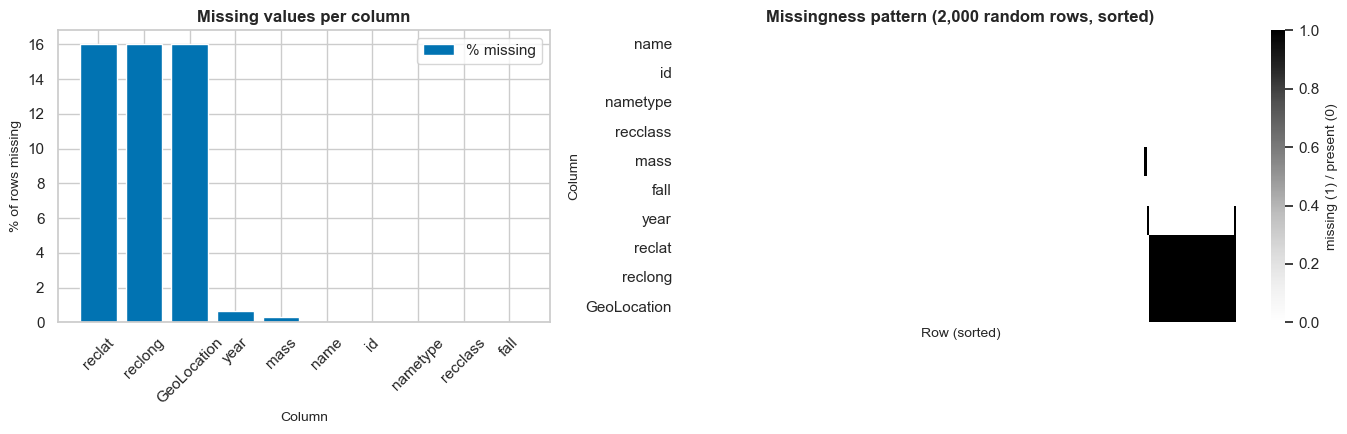

Rows missing reclat also missing reclong & GeoLocation: True


In [4]:
miss = raw.isna()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 1.4]})
pct = (miss.mean() * 100).sort_values(ascending=False)
axes[0].bar(pct.index, pct.values, color=PALETTE[0], label="% missing")
axes[0].set(title="Missing values per column", xlabel="Column", ylabel="% of rows missing"); axes[0].tick_params(axis="x", rotation=45); axes[0].legend()
sample = miss.sample(2000, random_state=RANDOM_STATE).sort_values(["reclat", "year", "mass"])
sns.heatmap(sample.T, cbar_kws={"label": "missing (1) / present (0)"}, cmap="Greys", ax=axes[1])
axes[1].set(title="Missingness pattern (2,000 random rows, sorted)", xlabel="Row (sorted)", ylabel="Column"); axes[1].set_xticks([])
fig.tight_layout(); save_fig(fig, TRACK, "eda_missing_values"); plt.show()
print("Rows missing reclat also missing reclong & GeoLocation:",
      bool((miss["reclat"] == miss["reclong"]).all() and (miss["reclat"] == miss["GeoLocation"]).all()))

### Observation — missingness
Coordinates are missing together: `reclat`, `reclong` and `GeoLocation` are always missing in the same rows, so the cause is one missing location record rather than three independent gaps. Missing mass and missing year are rare and scattered. Location is the core of this analysis and cannot be credibly imputed, so rows without a usable location are removed (§7).

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

### 6.2 Where are meteorites recorded? (raw coordinates)

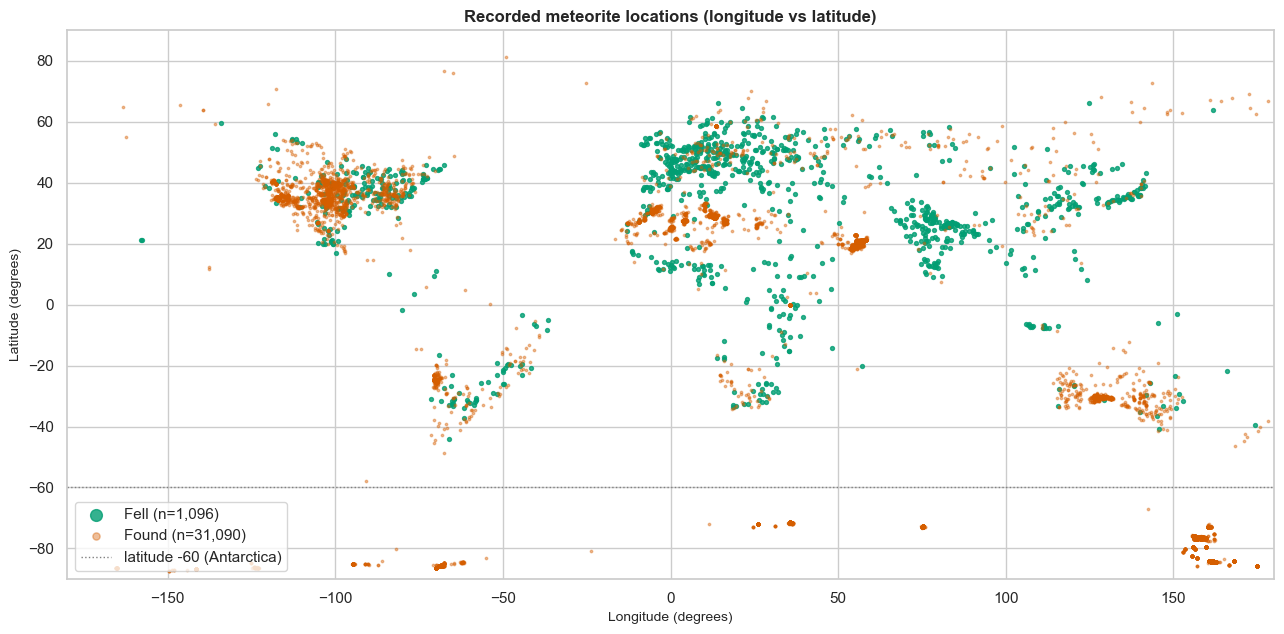

Share of located meteorites south of -60 deg latitude: 68.7%


In [5]:
geo = raw.dropna(subset=["reclat", "reclong"])
geo = geo[~((geo.reclat == 0) & (geo.reclong == 0)) & geo.reclong.between(-180, 180)]
fig, ax = plt.subplots(figsize=(13, 6.5))
for i, (label, grp) in enumerate(geo.groupby("fall")):
    ax.scatter(grp.reclong, grp.reclat, s=3 if label == "Found" else 8, alpha=0.4 if label == "Found" else 0.8,
               color=PALETTE[i + 2], label=f"{label} (n={len(grp):,})")
ax.set(title="Recorded meteorite locations (longitude vs latitude)", xlabel="Longitude (degrees)", ylabel="Latitude (degrees)",
       xlim=(-180, 180), ylim=(-90, 90))
ax.axhline(-60, color="grey", linestyle=":", linewidth=1, label="latitude -60 (Antarctica)")
ax.legend(markerscale=3, loc="lower left")
fig.tight_layout(); save_fig(fig, TRACK, "eda_world_scatter"); plt.show()
print(f"Share of located meteorites south of -60 deg latitude: {(geo.reclat < -60).mean():.1%}")

### Observation — geography
The points trace the world's land masses, but very unevenly. About two thirds of the located meteorites lie **south of −60°, in Antarctica**, and further dense patches appear in the Sahara / North-West Africa and Oman. **Found** meteorites concentrate where they are easy to spot and are searched for systematically (dark stones on ice and desert surfaces). **Fell** meteorites (seen falling) follow where people live, such as Europe, India and Japan. The data therefore reflects *where people look* at least as much as where meteorites land.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

### 6.3 Mass and year distributions

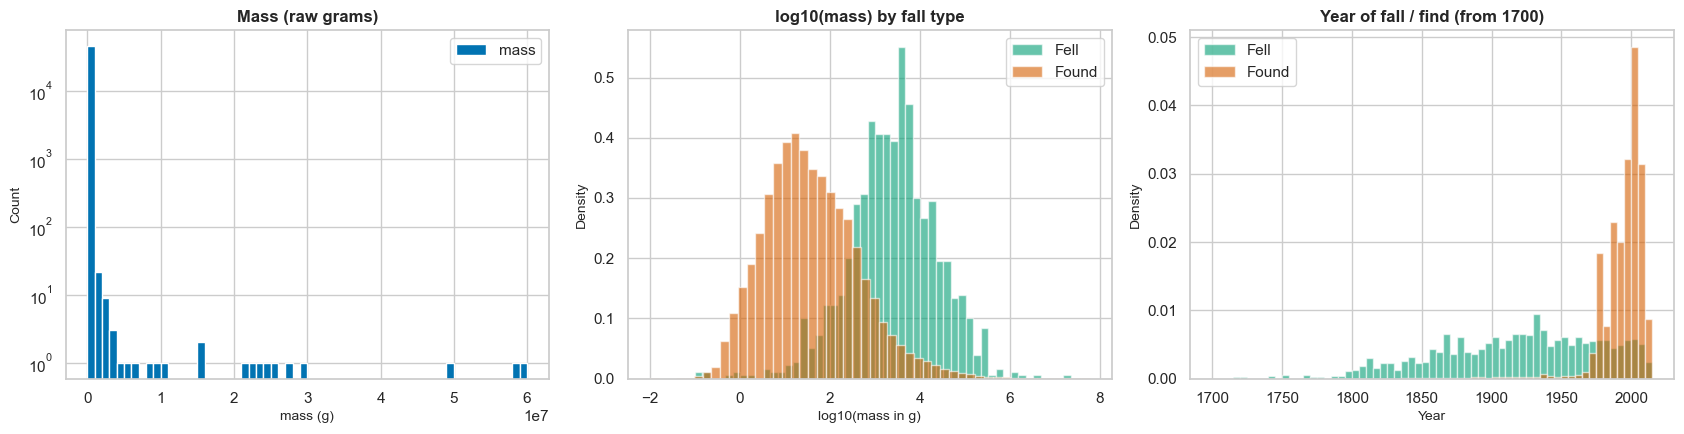

mass skewness (raw) = 76.7  |  log10(mass) skewness = 0.66
Median mass (g) by fall: {'Fell': 2800.0, 'Found': 30.0}
Median year by fall    : {'Fell': 1924.0, 'Found': 1998.0}


In [6]:
valid = raw[(raw.mass > 0) & raw.year.between(*config.CLU_VALID_YEAR_RANGE)]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].hist(valid.mass, bins=60, color=PALETTE[0], label="mass")
axes[0].set(title="Mass (raw grams)", xlabel="mass (g)", ylabel="Count", yscale="log"); axes[0].legend()
for i, (label, grp) in enumerate(valid.groupby("fall")):
    axes[1].hist(np.log10(grp.mass), bins=50, alpha=0.6, density=True, color=PALETTE[i + 2], label=label)
axes[1].set(title="log10(mass) by fall type", xlabel="log10(mass in g)", ylabel="Density"); axes[1].legend()
for i, (label, grp) in enumerate(valid.groupby("fall")):
    axes[2].hist(grp.year, bins=np.arange(1700, 2020, 5), alpha=0.6, density=True, color=PALETTE[i + 2], label=label)
axes[2].set(title="Year of fall / find (from 1700)", xlabel="Year", ylabel="Density"); axes[2].legend()
fig.tight_layout(); save_fig(fig, TRACK, "eda_mass_year_distributions"); plt.show()
print(f"mass skewness (raw) = {valid.mass.skew():.1f}  |  log10(mass) skewness = {np.log10(valid.mass).skew():.2f}")
print("Median mass (g) by fall:", valid.groupby("fall").mass.median().to_dict())
print("Median year by fall    :", valid.groupby("fall").year.median().to_dict())

### Observation — mass and year
- Raw mass is extremely right-skewed: most specimens weigh grams to kilograms, but the largest weighs 60 tonnes. In Euclidean distance the few giants would swamp everything else, so `log10(mass)` is used instead. It is far more symmetric (see the printed skewness values).
- Observed falls are heavier (median 2.8 kg vs 30 g for finds) and older (median year 1924 vs 1998). A meteorite that is seen falling tends to be large, while modern Antarctic and desert searches recover many small stones.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

### 6.4 Correlation heatmap of the numeric variables

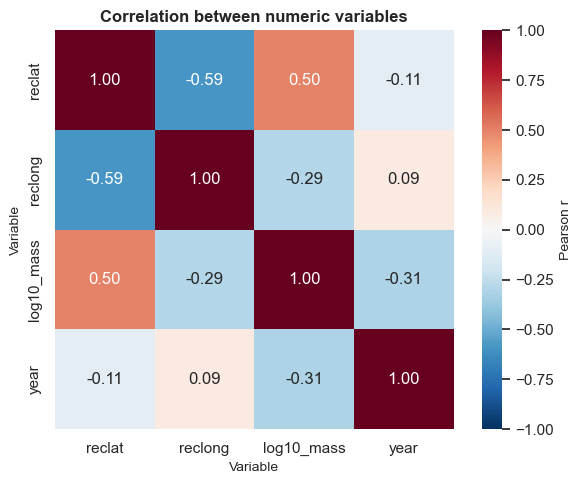

In [7]:
num = valid.dropna(subset=["reclat", "reclong"]).assign(log10_mass=lambda d: np.log10(d.mass))[["reclat", "reclong", "log10_mass", "year"]]
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, cbar_kws={"label": "Pearson r"}, ax=ax)
ax.set(title="Correlation between numeric variables", xlabel="Variable", ylabel="Variable")
fig.tight_layout(); save_fig(fig, TRACK, "eda_correlation_heatmap"); plt.show()

### Observation — correlations
- Latitude and log mass: r ≈ +0.50. Southern (Antarctic) finds are small.
- Latitude and longitude: r ≈ −0.59. This reflects *where* the dense collecting areas are (the Antarctic sites lie mostly at 75–165° E), not a physical law.
- Log mass and year: r ≈ −0.31. Older records are heavier.
- Latitude and year: only r ≈ −0.11.

These linear summaries suggest that location, mass and year carry **shared** structure, which is what clustering looks for. Pearson's r only captures linear trends, however, and the clusters themselves are non-linear groupings.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

## 7. Data cleaning

Each rule is applied in order by `src.preprocessing.clean_meteorites`, which logs how many rows it removes:

In [8]:
df, cleaning_log = clean_meteorites(raw)
display(cleaning_log)
print(f"Rows kept: {len(df):,} of {len(raw):,} ({len(df) / len(raw):.1%})")
print("Duplicates (ignoring name/id) kept on purpose:", int(df.drop(columns=["name", "id"]).duplicated().sum()))

,rule,rows_removed,rows_remaining
0,mass missing,131,45585
1,year missing,274,45311
2,coordinates missing,7195,38116
3,"placeholder coordinates (0, 0)",6186,31930
4,year outside 860-2016,1,31929
5,"longitude outside [-180, 180]",0,31929
6,mass equal to 0 g,18,31911


Rows kept: 31,911 of 45,716 (69.8%)
Duplicates (ignoring name/id) kept on purpose: 1571


### Decisions — cleaning
- **Remove rows without mass, year or location (no imputation).** Clustering is driven by these very features, so an imputed value would create artificial points. For example, filling missing coordinates with the mean would place meteorites in the middle of the ocean.
- **Remove the (0, 0) placeholders and impossible values** listed in §5. They are recording errors, not observations.
- **Keep duplicate-looking rows.** Specimens identical in everything except name and id are separate meteorites recovered at the same logged search site, common for Antarctic expeditions. They are real observations of the density we want to measure.
- **No outlier deletion.** Extreme masses are real (for example Hoba, 60 t) and are tamed by the log transform instead. Extreme old years are real historical falls.

The result keeps 31,911 meteorites (69.8% of the rows). 1,571 of the kept rows duplicate another kept row in every column except name and id.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

## 8. Feature selection, engineering and scaling

| Column | Used? | Reason |
|---|---|---|
| `reclat`, `reclong` | ✔ as **geo_x, geo_y, geo_z** | Location on the unit sphere (see below) |
| `mass` | ✔ as **log10_mass** | Removes extreme skew |
| `year` | ✔ | Era of fall / find |
| `name`, `id` | ✘ | Identifiers |
| `GeoLocation` | ✘ | Duplicates `reclat`/`reclong` |
| `nametype` | ✘ | 99.8% `Valid`, almost no variation |
| `fall`, `recclass` | ✘ (post hoc only) | Label-like columns: kept aside to **interpret** clusters, never to fit them |

**Why unit-sphere coordinates?** Longitude wraps around: −179.9° and +179.9° are about 22 km apart on the ground, but 359.8 units apart as raw numbers. Converting to $x = \cos\phi\cos\lambda,\ y = \cos\phi\sin\lambda,\ z = \sin\phi$ makes straight-line distance grow monotonically with true great-circle distance, so the clustering algorithms see real geographic proximity.

In [9]:
demo = pd.DataFrame({"reclat": [-70.0, -70.0], "reclong": [-179.9, 179.9], "mass": [1.0, 1.0]})
d = add_meteorite_features(demo)
print(f"Raw (lat, long) distance           : {np.hypot(*(demo[['reclat', 'reclong']].iloc[0] - demo[['reclat', 'reclong']].iloc[1])):.1f} degrees")
print(f"Unit-sphere (x, y, z) chord distance: {np.linalg.norm(d[['geo_x', 'geo_y', 'geo_z']].iloc[0] - d[['geo_x', 'geo_y', 'geo_z']].iloc[1]):.5f} Earth radii (~{np.linalg.norm(d[['geo_x', 'geo_y', 'geo_z']].iloc[0] - d[['geo_x', 'geo_y', 'geo_z']].iloc[1]) * 6371:.0f} km)")

pre = clustering_preprocessor()
Z = pre.fit_transform(df)   # engineered features -> StandardScaler (fitted on all cleaned rows: no labels, no test set)
features = config.CLU_MODEL_FEATURES
display(pd.DataFrame(Z, columns=features).describe().T.round(3))

Raw (lat, long) distance           : 359.8 degrees
Unit-sphere (x, y, z) chord distance: 0.00119 Earth radii (~8 km)


,count,mean,std,min,25%,50%,75%,max
geo_x,31911.0,-0.0,1.0,-2.918,-0.809,-0.130,0.452,2.474
geo_y,31911.0,-0.0,1.0,-3.206,-0.299,-0.108,0.315,2.412
geo_z,31911.0,-0.0,1.0,-0.680,-0.656,-0.604,1.404,2.473
log10_mass,31911.0,-0.0,1.0,-3.165,-0.712,-0.137,0.589,5.361
year,31911.0,0.0,1.0,-42.173,-0.186,0.150,0.487,0.974


**Scaling.** After engineering, the features have very different units (unit-sphere coordinates in [−1, 1], log mass from about −2 to 7.8, years in the hundreds to thousands). `StandardScaler` gives each feature mean 0 and standard deviation 1, so that no feature dominates the distance just because of its unit. There is no supervised train/test split here, so the scaler is fitted on all cleaned rows. This involves no leakage: no label or held-out set exists for information to leak from.

*Design consequence:* location is represented by three columns, so after scaling it carries more weight in the distance than mass or year (the three coordinates are correlated, so the extra weight is less than 3×). We accept this because geography is the dominant structure in the data. It is listed as a limitation in §15.

## 9. K-Means clustering
### 9.1 Choosing k: elbow curve plus three internal indices

K-Means minimises **inertia** (the within-cluster sum of squared distances), so inertia always falls as k grows. The *elbow* is where adding clusters stops paying off. Because an elbow is often ambiguous, the three required indices are also computed for every k:
- **Silhouette** (−1 to 1, **higher is better**): how much closer each point is to its own cluster than to the nearest other cluster.
- **Davies-Bouldin** (≥ 0, **lower is better**): the average worst-case ratio of within-cluster scatter to between-cluster separation.
- **Calinski-Harabasz** (≥ 0, **higher is better**): the ratio of between-cluster to within-cluster dispersion.

Silhouette costs O(n²), so during this scan it is estimated on a fixed random sample of 10,000 points (`random_state=42`). The final model's silhouette in §11 is computed exactly.

In [10]:
ks = range(2, 11)
scan = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z)
    m = clustering_metrics(Z, km.labels_, silhouette_sample=10_000)
    scan.append({"k": k, "inertia": km.inertia_, "Silhouette": m["Silhouette"], "Davies-Bouldin": m["Davies-Bouldin"],
                 "Calinski-Harabasz": m["Calinski-Harabasz"], "smallest cluster": int(np.bincount(km.labels_).min())})
scan = pd.DataFrame(scan)
scan.to_csv(config.RESULTS_DIR / "clustering_k_selection.csv", index=False)
display(scan.round(4))
best_k = {"Silhouette": int(scan.loc[scan["Silhouette"].idxmax(), "k"]),
          "Davies-Bouldin": int(scan.loc[scan["Davies-Bouldin"].idxmin(), "k"]),
          "Calinski-Harabasz": int(scan.loc[scan["Calinski-Harabasz"].idxmax(), "k"])}
print("Best k according to each index:", best_k)

,k,inertia,Silhouette,Davies-Bouldin,Calinski-Harabasz,smallest cluster
0,2,104197.2735,0.5188,1.1710,16952.5604,8302
1,3,71955.5283,0.5554,0.9691,19422.5904,2570
2,4,58396.9854,0.5747,0.9236,18423.6096,1095
3,5,50433.3724,0.3266,1.1361,17258.7039,1058
4,6,44459.3050,0.3263,1.0752,16519.4649,1026
5,7,39712.8793,0.3698,0.9979,16046.2983,1014
6,8,35662.4439,0.3732,1.0246,15833.2418,710
7,9,31856.3371,0.3844,0.9586,15985.2133,547
8,10,29601.9102,0.3806,0.9314,15560.6998,547


Best k according to each index: {'Silhouette': 4, 'Davies-Bouldin': 4, 'Calinski-Harabasz': 3}


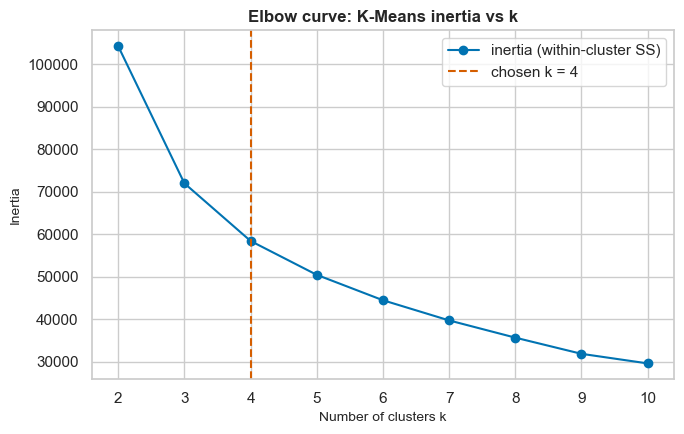

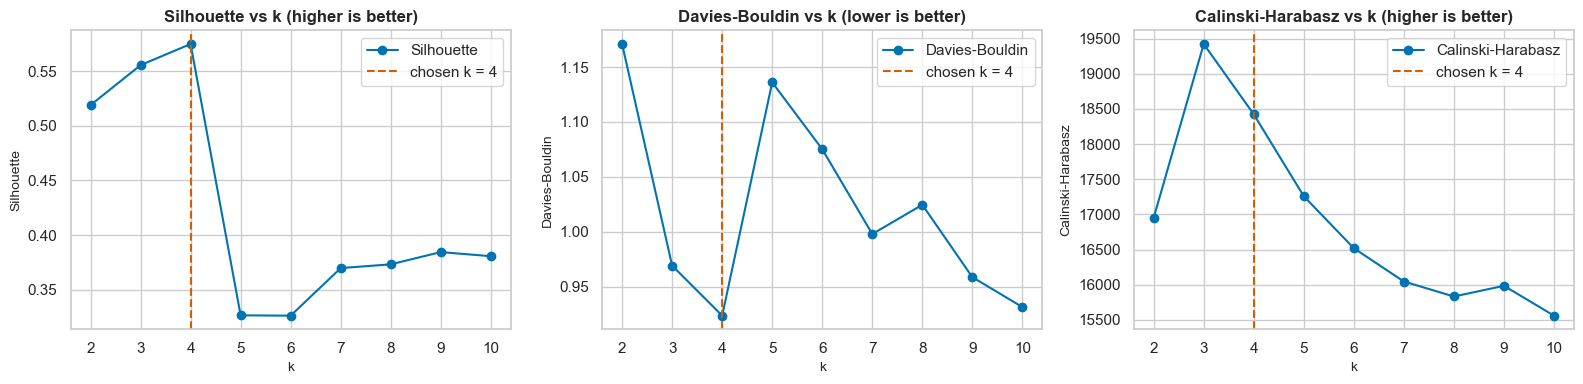

Chosen k = 4 (majority vote of the three indices: {'Silhouette': 4, 'Davies-Bouldin': 4, 'Calinski-Harabasz': 3})


In [11]:
K = max(set(best_k.values()), key=list(best_k.values()).count)   # majority vote of the three indices
fig = plot_elbow(list(ks), scan["inertia"], K)
save_fig(fig, TRACK, "kmeans_elbow_curve"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (metric, better) in zip(axes, [("Silhouette", "higher"), ("Davies-Bouldin", "lower"), ("Calinski-Harabasz", "higher")]):
    ax.plot(scan["k"], scan[metric], marker="o", color=PALETTE[0], label=metric)
    ax.axvline(K, color=PALETTE[3], linestyle="--", label=f"chosen k = {K}")
    ax.set(title=f"{metric} vs k ({better} is better)", xlabel="k", ylabel=metric); ax.legend()
fig.tight_layout(); save_fig(fig, TRACK, "kmeans_metrics_vs_k"); plt.show()
print(f"Chosen k = {K} (majority vote of the three indices: {best_k})")

### Decision — number of clusters: k = 4
- **Elbow:** inertia falls steeply from k = 2 to 4 (104,197 → 71,956 → 58,397) and more slowly after that. The bend is around k = 3–4, which is suggestive but not decisive on its own.
- **Silhouette** peaks at **k = 4** (0.575), then **drops sharply at k = 5 (0.327)**. Splitting further breaks a natural group.
- **Davies-Bouldin** is lowest at **k = 4** (0.924).
- **Calinski-Harabasz** prefers k = 3 (19,423 vs 18,424 at k = 4), so the indices do not fully agree.
- Two of three indices plus the elbow point to **k = 4**. It also passes a practical check: its smallest cluster still holds 1,095 meteorites (3.4%), so it is not a handful of outliers.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

### 9.2 Final K-Means model and a stability check

In [12]:
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(Z)
df["kmeans"] = kmeans.labels_
print("Cluster sizes:", np.bincount(kmeans.labels_).tolist(), "| inertia:", round(kmeans.inertia_, 1), "| iterations:", kmeans.n_iter_)

# Stability (the unsupervised stand-in for cross-validation): refit on 10 bootstrap resamples and with 10 other seeds,
# then compare each new partition of ALL points with the reference partition using the Adjusted Rand Index (1 = identical).
rng = np.random.RandomState(RANDOM_STATE)
boot_ari = [adjusted_rand_score(kmeans.labels_, KMeans(K, n_init=10, random_state=RANDOM_STATE).fit(Z[rng.choice(len(Z), len(Z))]).predict(Z))
            for _ in range(10)]
seed_ari = [adjusted_rand_score(kmeans.labels_, KMeans(K, n_init=10, random_state=s).fit(Z).labels_) for s in range(1, 11)]
stability = {"bootstrap_ari_mean": float(np.mean(boot_ari)), "bootstrap_ari_min": float(np.min(boot_ari)),
             "seed_ari_mean": float(np.mean(seed_ari)), "seed_ari_min": float(np.min(seed_ari))}
print({k: round(v, 4) for k, v in stability.items()})

Cluster sizes: [6152, 1997, 22667, 1095] | inertia: 58397.0 | iterations: 7


{'bootstrap_ari_mean': 0.9992, 'bootstrap_ari_min': 0.9988, 'seed_ari_mean': 0.9999, 'seed_ari_min': 0.9999}


### Observation — stability
The k = 4 partition is **very stable**. Refitting on 10 bootstrap resamples reproduces it with a mean Adjusted Rand Index of 0.999 (minimum 0.999), and changing the random seed gives ARI 0.9999. The clusters are therefore a property of the data, not an accident of initialisation or of which rows happened to be sampled. This plays the role that cross-validation plays in the supervised tracks.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

## 10. Agglomerative hierarchical clustering
### 10.1 Why a sample, and which sample

Standard agglomerative clustering needs every pairwise distance. For 31,911 points that is about 509 million distances, roughly **4.1 GB** of memory as 64-bit floats, plus O(n²) time for every linkage tried. To keep the analysis practical and reproducible, agglomerative clustering is fitted on a **uniform random sample of 10,000 meteorites** (`random_state=42`, 31% of the data). K-Means is evaluated on **the same sample** as well, so the comparison in §11 is like-for-like.

In [13]:
sample_idx = np.sort(np.random.RandomState(RANDOM_STATE).choice(len(Z), config.CLU_AGGLO_SAMPLE_SIZE, replace=False))
Zs = Z[sample_idx]
print(f"Sample: {len(Zs):,} points | pairwise distances: {len(Zs) * (len(Zs) - 1) // 2:,} "
      f"(full data would need {len(Z) * (len(Z) - 1) // 2 * 8 / 1e9:.1f} GB)")
summary_cols = lambda d: pd.DataFrame({"reclat": d.reclat, "log10_mass": np.log10(d.mass), "year": d.year})
comp = pd.DataFrame({"full data": summary_cols(df).median(), "sample": summary_cols(df.iloc[sample_idx]).median()})
print("Sample is representative (medians of lat, log10 mass, year):"); display(comp.round(3))

Sample: 10,000 points | pairwise distances: 49,995,000 (full data would need 4.1 GB)
Sample is representative (medians of lat, log10 mass, year):


,full data,sample
reclat,-72.000,-72.000
log10_mass,1.472,1.452
year,1991.000,1991.000


### 10.2 Comparing linkage strategies

In [14]:
linkage_rows, linkage_labels = [], {}
for method in ["ward", "complete", "average", "single"]:
    t0 = time.perf_counter()
    labels = AgglomerativeClustering(n_clusters=K, linkage=method).fit_predict(Zs)
    secs = time.perf_counter() - t0
    m = clustering_metrics(Zs, labels)
    sizes = np.bincount(labels)
    linkage_labels[method] = labels
    linkage_rows.append({"linkage": method, "Silhouette": m["Silhouette"], "Davies-Bouldin": m["Davies-Bouldin"],
                         "Calinski-Harabasz": m["Calinski-Harabasz"], "cluster sizes": sorted(sizes.tolist(), reverse=True),
                         "smallest cluster %": 100 * sizes.min() / len(Zs), "fit seconds": secs})
linkage_cmp = pd.DataFrame(linkage_rows)
linkage_cmp.to_csv(config.RESULTS_DIR / "clustering_linkage_comparison.csv", index=False)
display(linkage_cmp.round(4))

# Selection rule: discard degenerate partitions (smallest cluster < 1% of the sample), then take the best silhouette.
usable = linkage_cmp[linkage_cmp["smallest cluster %"] >= 1.0]
LINKAGE = usable.loc[usable["Silhouette"].idxmax(), "linkage"]
print(f"Selected linkage: {LINKAGE}  (non-degenerate linkages: {usable['linkage'].tolist()})")

,linkage,Silhouette,Davies-Bouldin,Calinski-Harabasz,cluster sizes,smallest cluster %,fit seconds
0,ward,0.5693,0.9673,5212.7144,"[7113, 1868, 708, 311]",3.11,1.3709
1,complete,0.6040,0.5267,527.4897,"[9882, 111, 6, 1]",0.01,1.1175
2,average,0.5752,0.5780,713.6104,"[9772, 221, 6, 1]",0.01,1.2002
3,single,0.8028,0.1097,152.6513,"[9997, 1, 1, 1]",0.01,0.3685


Selected linkage: ward  (non-degenerate linkages: ['ward'])


### Observation — linkages
- **Single, complete and average linkage are degenerate.** Each puts ≥ 97.7% of the sample into one cluster and isolates a few outliers (for example single linkage gives sizes 9,997 / 1 / 1 / 1). Single linkage nevertheless has the **highest silhouette (0.803) and the lowest Davies-Bouldin (0.110)** of all four. This is a useful warning: internal indices can reward a partition that is useless for interpretation, so cluster sizes must be checked as well.
- **Ward linkage** merges the pair of clusters whose union least increases within-cluster variance, which is the same objective as K-Means. It gives balanced, meaningful groups (7,113 / 1,868 / 708 / 311) with silhouette 0.569 and by far the highest Calinski-Harabasz (5,213). It is the only non-degenerate linkage and is selected.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

### 10.3 Dendrogram

The dendrogram is built with SciPy's `linkage` on the same 10,000-point sample, using the selected linkage. It is truncated to the last 40 merges so that it stays readable. The dashed line marks the height where the tree is cut into k clusters. Cutting the SciPy tree must reproduce scikit-learn's labels exactly, and the Adjusted Rand Index check below confirms that it does.

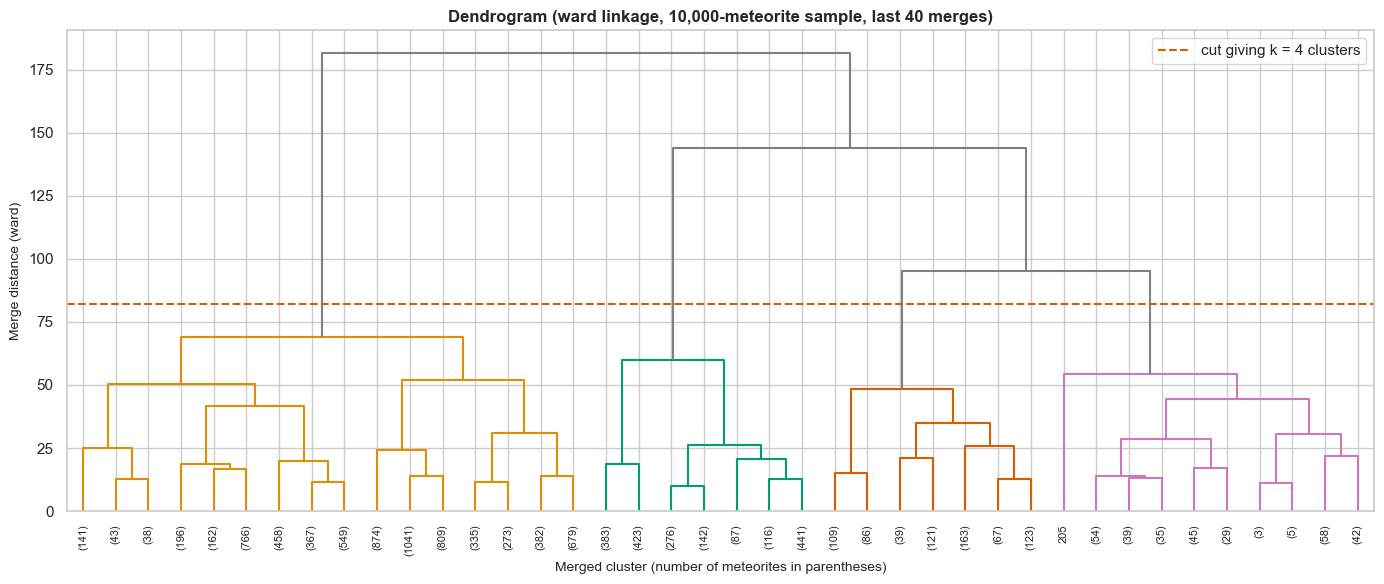

ARI between SciPy dendrogram cut and scikit-learn labels: 1.0
Merge heights of the last 6 merges: [54.3, 59.9, 69.1, 95.1, 143.8, 181.4]


In [15]:
Lmat = linkage(Zs, method=LINKAGE)
cut = (Lmat[-K, 2] + Lmat[-(K - 1), 2]) / 2
fig, ax = plt.subplots(figsize=(14, 6))
dendrogram(Lmat, truncate_mode="lastp", p=40, show_leaf_counts=True, leaf_rotation=90, leaf_font_size=8,
           color_threshold=cut, above_threshold_color="grey", ax=ax)
ax.axhline(cut, color=PALETTE[3], linestyle="--", label=f"cut giving k = {K} clusters")
ax.set(title=f"Dendrogram ({LINKAGE} linkage, 10,000-meteorite sample, last 40 merges)",
       xlabel="Merged cluster (number of meteorites in parentheses)", ylabel=f"Merge distance ({LINKAGE})")
ax.legend(); fig.tight_layout(); save_fig(fig, TRACK, "agglomerative_dendrogram"); plt.show()

agglo = AgglomerativeClustering(n_clusters=K, linkage=LINKAGE).fit(Zs)
print("ARI between SciPy dendrogram cut and scikit-learn labels:",
      round(adjusted_rand_score(fcluster(Lmat, K, criterion="maxclust"), agglo.labels_), 6))
print("Merge heights of the last 6 merges:", np.round(Lmat[-6:, 2], 1).tolist())

### Observation — dendrogram
The last merges happen at heights 95, 144 and 181, far above every earlier merge (≤ 69). Cutting between 69 and 95 (dashed line) yields **four well-separated branches**, so the hierarchy independently supports k = 4. Cutting the SciPy tree reproduces scikit-learn's labels exactly (ARI = 1.0).

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

## 11. Evaluation metrics for both algorithms (R2-B2)

| Index | Range | Better |
|---|---|---|
| Silhouette | −1 to 1 | **higher** |
| Davies-Bouldin | 0 to ∞ | **lower** |
| Calinski-Harabasz | 0 to ∞ | **higher** |

K-Means is reported twice: on all 31,911 meteorites, and on the 10,000-point sample shared with agglomerative clustering, which is the like-for-like comparison. The agreement between the two partitions on the sample is also measured with the Adjusted Rand Index.

,Algorithm,Evaluated on,Silhouette,Davies-Bouldin,Calinski-Harabasz,n_clusters
0,K-Means,"all 31,911 rows",0.5741,0.9236,18423.6096,4
1,K-Means,"10,000-row sample",0.5747,0.9200,5521.5247,4
2,Agglomerative (ward),"10,000-row sample",0.5693,0.9673,5212.7144,4


Agreement between K-Means and agglomerative on the sample: ARI = 0.979, NMI = 0.924
(exact silhouette on all rows took 8.8 s)


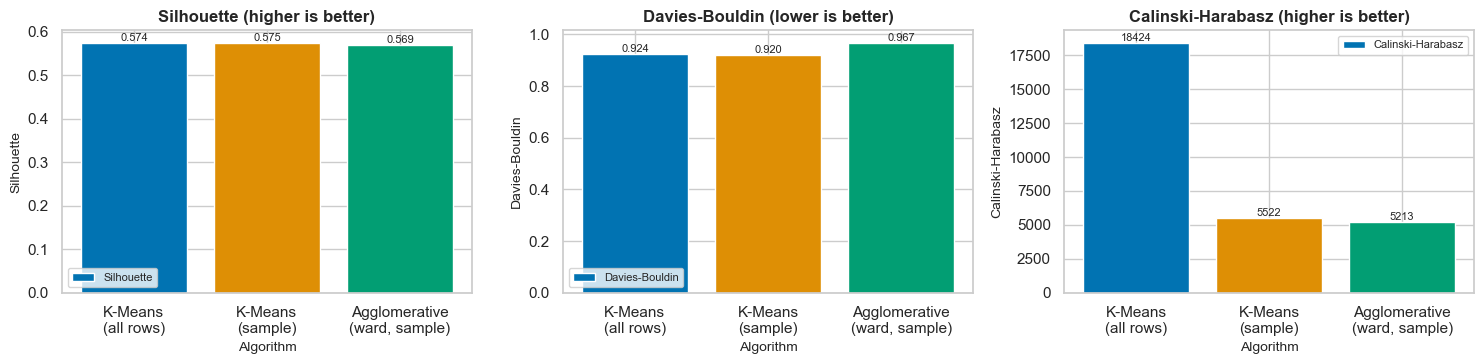

In [16]:
t0 = time.perf_counter(); km_full = clustering_metrics(Z, kmeans.labels_); t_full = time.perf_counter() - t0
km_sample = clustering_metrics(Zs, kmeans.labels_[sample_idx])
ag_sample = clustering_metrics(Zs, agglo.labels_)
results = pd.DataFrame([
    {"Algorithm": "K-Means", "Evaluated on": f"all {len(Z):,} rows", **km_full},
    {"Algorithm": "K-Means", "Evaluated on": f"{len(Zs):,}-row sample", **km_sample},
    {"Algorithm": f"Agglomerative ({LINKAGE})", "Evaluated on": f"{len(Zs):,}-row sample", **ag_sample},
]).drop(columns="note")
results.to_csv(config.RESULTS_DIR / "clustering_results.csv", index=False)
display(results.round(4))
ari_methods = adjusted_rand_score(kmeans.labels_[sample_idx], agglo.labels_)
print(f"Agreement between K-Means and agglomerative on the sample: ARI = {ari_methods:.3f}, "
      f"NMI = {normalized_mutual_info_score(kmeans.labels_[sample_idx], agglo.labels_):.3f}")
print(f"(exact silhouette on all rows took {t_full:.1f} s)")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
labels_ = ["K-Means\n(all rows)", "K-Means\n(sample)", f"Agglomerative\n({LINKAGE}, sample)"]
for ax, (metric, better) in zip(axes, [("Silhouette", "higher"), ("Davies-Bouldin", "lower"), ("Calinski-Harabasz", "higher")]):
    bars = ax.bar(labels_, results[metric], color=PALETTE[:3], label=metric)
    ax.bar_label(bars, fmt="%.3f" if metric != "Calinski-Harabasz" else "%.0f", fontsize=8)
    ax.set(title=f"{metric} ({better} is better)", xlabel="Algorithm", ylabel=metric); ax.legend(fontsize=8)
fig.tight_layout(); save_fig(fig, TRACK, "metric_comparison"); plt.show()

### Observation — metric comparison
- On the shared 10,000-row sample, K-Means scores slightly better than Ward agglomerative on all three indices: silhouette 0.575 vs 0.569, Davies-Bouldin 0.920 vs 0.967, Calinski-Harabasz 5,522 vs 5,213. K-Means directly optimises within-cluster variance, which these indices reward.
- The two algorithms largely **agree** (ARI = 0.979, NMI = 0.924), so the four groups are not an artefact of one method.
- K-Means' metrics on all 31,911 rows (silhouette 0.574) match its sample metrics, which confirms the sample is representative. (Calinski-Harabasz grows with n, so it is only comparable between rows evaluated on the same data.)
- A silhouette of about 0.57 indicates reasonable but not crisp separation. Some meteorites lie between groups.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

## 12. Cluster visualisation (R2-B3)
### 12.1 PCA projection (2 principal components) for both algorithms

PCA is fitted on the full scaled data. **A 2-D projection keeps only part of the variance**, so clusters that are well separated in 5-D can overlap in the plot. The printed explained-variance ratio says how much of the original spread the picture shows.

Explained variance: PC1 40.8%, PC2 28.4%, total 69.2%


,geo_x,geo_y,geo_z,log10_mass,year
PC1,0.478,0.109,0.624,0.540,-0.280
PC2,0.442,0.661,0.023,-0.269,0.543


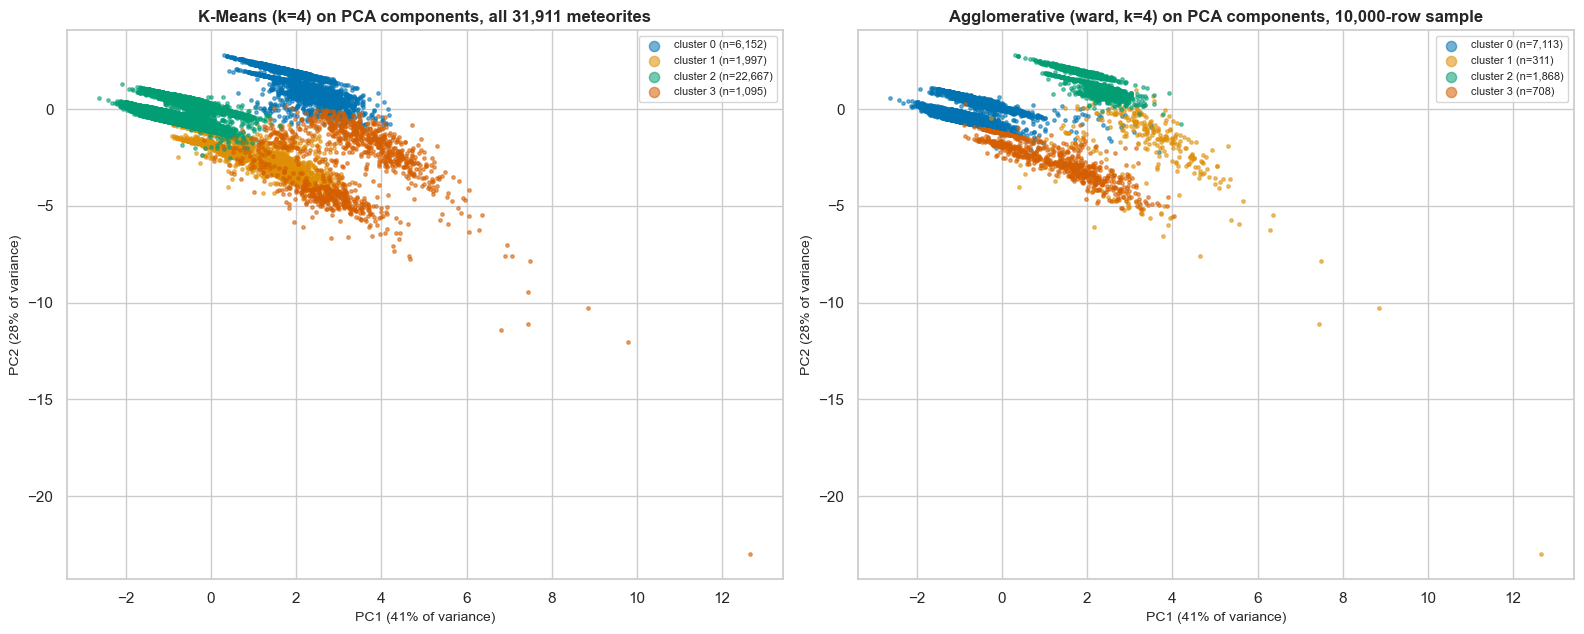

In [17]:
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(Z)
P = pca.transform(Z)
ev = pca.explained_variance_ratio_
print(f"Explained variance: PC1 {ev[0]:.1%}, PC2 {ev[1]:.1%}, total {ev.sum():.1%}")
display(pd.DataFrame(pca.components_, index=["PC1", "PC2"], columns=features).round(3))
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
plot_clusters_2d(P, kmeans.labels_, f"K-Means (k={K}) on PCA components, all {len(Z):,} meteorites",
                 f"PC1 ({ev[0]:.0%} of variance)", f"PC2 ({ev[1]:.0%} of variance)", ax=axes[0])
plot_clusters_2d(P[sample_idx], agglo.labels_, f"Agglomerative ({LINKAGE}, k={K}) on PCA components, {len(Zs):,}-row sample",
                 f"PC1 ({ev[0]:.0%} of variance)", f"PC2 ({ev[1]:.0%} of variance)", ax=axes[1])
fig.tight_layout(); save_fig(fig, TRACK, "pca_clusters_both"); plt.show()

### 12.2 t-SNE (on a 4,000-point subsample)

t-SNE is a non-linear projection that preserves **local neighbourhoods**. Distances *between* far-apart groups, and the apparent sizes of the groups, are **not meaningful** in a t-SNE plot. It is used here only to see whether each cluster forms a coherent region. t-SNE scales poorly with n, so 4,000 points are drawn from the 10,000-point sample, and both algorithms are coloured on the same embedding.

t-SNE on 4,000 points took 6.9 s


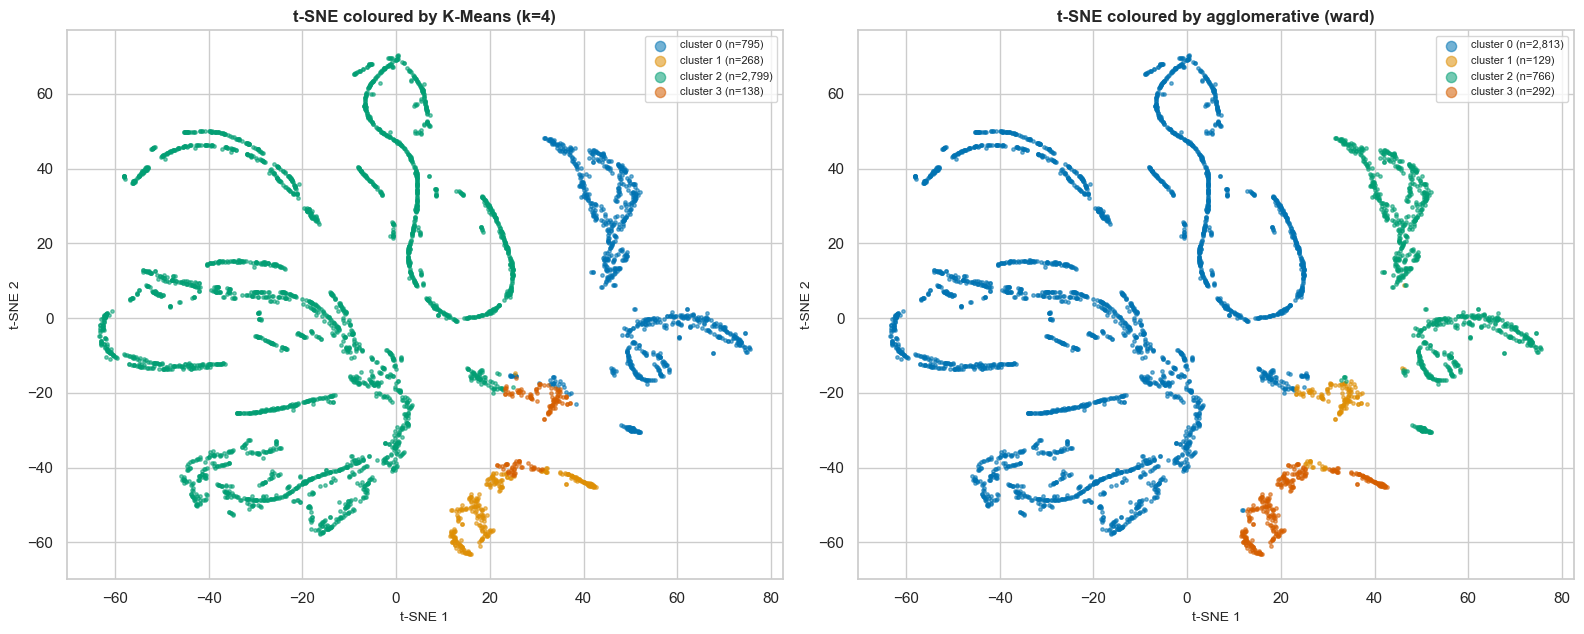

In [18]:
sub = np.sort(np.random.RandomState(RANDOM_STATE).choice(len(Zs), config.CLU_TSNE_SAMPLE_SIZE, replace=False))
t0 = time.perf_counter()
T = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=RANDOM_STATE).fit_transform(Zs[sub])
print(f"t-SNE on {len(sub):,} points took {time.perf_counter() - t0:.1f} s")
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
plot_clusters_2d(T, kmeans.labels_[sample_idx][sub], f"t-SNE coloured by K-Means (k={K})", "t-SNE 1", "t-SNE 2", ax=axes[0])
plot_clusters_2d(T, agglo.labels_[sub], f"t-SNE coloured by agglomerative ({LINKAGE})", "t-SNE 1", "t-SNE 2", ax=axes[1])
fig.tight_layout(); save_fig(fig, TRACK, "tsne_clusters_both"); plt.show()

### 12.3 The clusters on the map

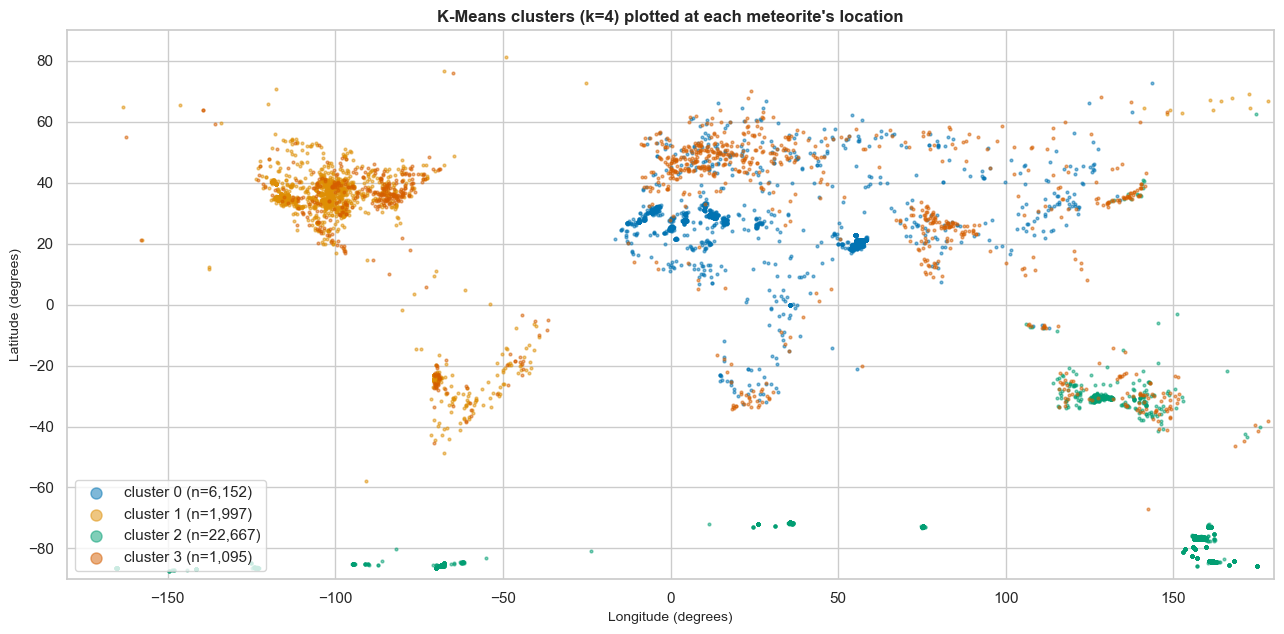

In [19]:
fig, ax = plt.subplots(figsize=(13, 6.5))
for c in range(K):
    m = df["kmeans"] == c
    ax.scatter(df.loc[m, "reclong"], df.loc[m, "reclat"], s=4, alpha=0.5, color=PALETTE[c], label=f"cluster {c} (n={m.sum():,})")
ax.set(title=f"K-Means clusters (k={K}) plotted at each meteorite's location", xlabel="Longitude (degrees)", ylabel="Latitude (degrees)",
       xlim=(-180, 180), ylim=(-90, 90))
ax.legend(markerscale=4, loc="lower left"); fig.tight_layout(); save_fig(fig, TRACK, "kmeans_world_map"); plt.show()

### Observation — visualisations
- **PCA:** the two components keep 69.2% of the variance. PC1 combines southern hemisphere vs northern (`geo_z`) with mass; PC2 combines longitude with year. Both algorithms produce the same arrangement of groups, with overlap at the boundaries. The far-right tail is a handful of very old historical falls. Year 860 is 42 standard deviations below the mean year, which shows how extreme the oldest records are after scaling.
- **t-SNE:** each cluster occupies its own regions of the embedding, and the K-Means and agglomerative colourings look almost identical, consistent with ARI = 0.979.
- **Map:** the clusters correspond to recognisable regions. Antarctica (plus Australia's Nullarbor desert finds) forms one cluster; the Sahara, Arabia and the Middle East another; the Americas a third. The fourth is spread worldwide over populated areas: Europe, India, Japan and the eastern USA.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

## 13. Cluster profiles and after-the-fact interpretation

Only now, after fitting, are the held-back label-like columns brought in: `fall` and `recclass`. They did not influence the clusters. They are used to check whether the clusters correspond to something real.

In [20]:
profile = df.groupby("kmeans").agg(
    n=("id", "size"), median_lat=("reclat", "median"), median_long=("reclong", "median"),
    median_mass_g=("mass", "median"), median_year=("year", "median"),
    pct_antarctic=("reclat", lambda s: 100 * (s < -60).mean()),
    pct_fell=("fall", lambda s: 100 * (s == "Fell").mean()),
    top_recclass=("recclass", lambda s: ", ".join(s.value_counts().head(3).index)),
)
profile["share_%"] = 100 * profile["n"] / len(df)
display(profile.round(1))
print(f"Overall share of observed falls: {100 * (df.fall == 'Fell').mean():.1f}%")
display(pd.crosstab(df["kmeans"], df["fall"], normalize="columns").round(3).rename_axis("cluster \\ fall (column %)"))
print(f"External agreement with fall (post hoc only): ARI = {adjusted_rand_score(df.fall, df.kmeans):.3f}, "
      f"NMI = {normalized_mutual_info_score(df.fall, df.kmeans):.3f}")

agg_profile = df.iloc[sample_idx].assign(agglo=agglo.labels_).groupby("agglo").agg(
    n=("id", "size"), median_lat=("reclat", "median"), median_long=("reclong", "median"),
    median_mass_g=("mass", "median"), median_year=("year", "median"), pct_fell=("fall", lambda s: 100 * (s == "Fell").mean()))
print("Agglomerative clusters on the sample:"); display(agg_profile.round(1))

,n,median_lat,median_long,median_mass_g,median_year,pct_antarctic,pct_fell,top_recclass,share_%
kmeans,,,,,,,,,
0,6152,20.9,54.0,250.7,2000.0,0.0,5.0,"L6, H5, H6",19.3
1,1997,34.3,-101.8,770.0,1982.0,0.0,7.9,"H5, L6, H4",6.3
2,22667,-76.3,156.0,14.0,1990.0,97.5,0.1,"L6, H5, H4",71.0
3,1095,36.8,12.6,6400.0,1887.0,0.1,52.4,"L6, Iron, IIIAB, H5",3.4


Overall share of observed falls: 3.3%


fall,Fell,Found
cluster \ fall (column %),,
0,0.287,0.190
1,0.148,0.060
2,0.025,0.734
3,0.539,0.017


External agreement with fall (post hoc only): ARI = 0.128, NMI = 0.122
Agglomerative clusters on the sample:


,n,median_lat,median_long,median_mass_g,median_year,pct_fell
agglo,,,,,,
0,7113,-76.2,155.8,13.6,1990.0,0.4
1,311,37.1,23.8,4500.0,1891.0,62.4
2,1868,20.7,54.0,246.5,2001.0,2.2
3,708,34.5,-101.5,954.5,1976.0,8.6


### Interpretation — what the clusters mean (K-Means, k = 4)
| Cluster | Size | Profile | Reading |
|---|---|---|---|
| 2 | 22,667 (71%) | median latitude −76°, **median mass 14 g**, 97.5% Antarctic, 0.1% falls | **Antarctic search finds**: tiny stones recovered on blue-ice fields |
| 0 | 6,152 (19%) | median 21° N, 54° E, 251 g, median year 2000 | **Hot-desert finds** (Sahara, Oman, Middle East) from modern collecting |
| 1 | 1,997 (6%) | median 34° N, 102° W, 770 g, year 1982 | **Americas finds** (US Great Plains, South-west, Chile/Argentina) |
| 3 | 1,095 (3%) | median 37° N, **6.4 kg**, **median year 1887**, **52.4% observed falls** | **Historical, heavy, often witnessed meteorites** in populated regions |

**After-the-fact check with `fall` (never used for fitting):** observed falls make up 3.3% of all meteorites but **52.4% of cluster 3**, and 53.9% of all observed falls land in that one cluster. Cluster 2 contains only 2.5% of falls. The agreement is not one-to-one (ARI with `fall` = 0.128), and it should not be, because `fall` is binary while the clusters describe four regions and eras. But it confirms that the unsupervised grouping recovered a real distinction between *witnessed historical falls* and *systematic modern searches*. `recclass` is dominated by ordinary chondrites (L6, H5) in every cluster, so the clusters are not about meteorite type. Cluster 3 alone has an iron class (Iron, IIIAB) among its top classes, which fits: large iron meteorites survive and get noticed.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

## 14. Saving the clustering artefacts

- `models/clustering/k_means.joblib`: the **complete** K-Means pipeline (feature engineering → scaler → KMeans). The app uses it to assign a **new** meteorite to its nearest centroid with exactly the training-time preprocessing.
- `models/clustering/pca_projection.joblib`: the fitted PCA, used to place new points on the app's PCA plot.
- Assignment tables and cluster profiles for the app's retrospective explorer.

**Agglomerative clustering has no `predict` method.** It builds a hierarchy over the points it was given and defines no rule for placing a new point. So it is saved only as **retrospective assignments for the 10,000-row sample**, and the app does not claim to assign new records with it.

In [21]:
kmeans_pipeline = Pipeline(clustering_preprocessor().steps + [("model", KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE))])
kmeans_pipeline.fit(df)
assert (kmeans_pipeline.predict(df) == kmeans.labels_).all(), "saved pipeline does not reproduce the notebook clusters"
save_pipeline(kmeans_pipeline, TRACK, "K-Means", {"task": "clustering", "k": K, "features_raw": config.CLU_RAW_FEATURES,
                                                  "features_model": features, "metrics_all_rows": km_full, "stability": stability})
save_pipeline(pca, TRACK, "PCA projection", {"task": "projection", "explained_variance_ratio": ev.tolist()})

out = ensure_dir(config.MODELS_DIR / TRACK)
cols = ["name", "reclat", "reclong", "mass", "year", "fall", "recclass"]
df[cols].assign(cluster=kmeans.labels_, pc1=P[:, 0].round(4), pc2=P[:, 1].round(4)).to_csv(out / "kmeans_assignments.csv", index=False)
df.iloc[sample_idx][cols].assign(cluster=agglo.labels_, pc1=P[sample_idx, 0].round(4), pc2=P[sample_idx, 1].round(4)).to_csv(
    out / "agglomerative_sample_assignments.csv", index=False)
save_json({"k": K, "linkage": LINKAGE, "agglomerative_sample_size": len(Zs), "metrics": results.to_dict(orient="records"),
           "kmeans_vs_agglomerative_ari": ari_methods, "stability": stability, "k_votes": best_k,
           "kmeans_profile": profile.reset_index().to_dict(orient="records"),
           "agglomerative_profile": agg_profile.reset_index().to_dict(orient="records"),
           "raw_feature_ranges": {c: [float(df[c].min()), float(df[c].max())] for c in config.CLU_RAW_FEATURES},
           "pca_explained_variance": ev.tolist()}, out / "clustering_summary.json")
for f in sorted(out.iterdir()):
    print(f"{f.name:42s} {f.stat().st_size / 1024:9.1f} KB")

agglomerative_sample_assignments.csv           736.6 KB
clustering_summary.json                          3.7 KB
k_means.joblib                                   4.8 KB
k_means.json                                     0.8 KB
kmeans_assignments.csv                        2351.8 KB
pca_projection.joblib                            0.8 KB
pca_projection.json                              0.3 KB


## 15. Limitations
- **Sampling bias drives the structure.** The clusters describe where and when meteorites were *recovered* (Antarctic expeditions, desert collecting), not where they *fall*. Real falls are spread roughly evenly over the globe.
- **Feature weighting is a modelling choice.** Location uses three standardised coordinates, so it carries more weight than mass or year. Other weightings would produce different clusters.
- **K-Means assumes compact, roughly spherical clusters** of similar spread, and is sensitive to scaling. The internal indices share that bias, so a high silhouette does not prove the clusters are "true".
- **Agglomerative results come from a 10,000-row random sample** (31% of the data), forced by O(n²) memory. They should be read as an estimate of the full-data hierarchy.
- PCA and t-SNE plots are 2-D projections and can hide or exaggerate separation.
- 13,805 rows (30%) were removed for missing or invalid location, mass or year, mostly missing or placeholder coordinates.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

## 16. Conclusion
- After removing missing and invalid records (31,911 of 45,716 kept) and engineering unit-sphere coordinates and log mass, both required algorithms were fitted: **K-Means** on all rows, and **Ward agglomerative clustering** on a documented 10,000-row sample.
- **k = 4** is supported by the silhouette and Davies-Bouldin indices, the elbow, the dendrogram's largest gaps and a bootstrap stability check (ARI 0.999). Calinski-Harabasz alone preferred k = 3.
- Both algorithms find essentially the same four groups (ARI 0.979). K-Means scores slightly better on all three internal indices (silhouette 0.575 vs 0.569 on the shared sample).
- The groups are interpretable: Antarctic search finds, hot-desert finds, Americas finds, and historical heavy falls. The held-out `fall` label confirms the last group after the fact. The main lesson is that the structure describes **how meteorites are collected**, not where they fall.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

---
**References.** NASA Open Data Portal, *Meteorite Landings* (data from The Meteoritical Society). scikit-learn user guide (clustering, clustering evaluation, PCA, t-SNE), https://scikit-learn.org/stable/user_guide.html. SciPy hierarchical clustering (`scipy.cluster.hierarchy`). AI assistance is disclosed at the top of this notebook and in the README.